In [7]:
# wavelength interpolation

import dLux as dl
import jax.numpy as np
import jax
import matplotlib.pyplot as plt
import dLux.utils as dlu
from dLux.sources import Source
from jax import Array
from dLux.sources import BaseSource
from jax import vmap
import jax.random as jr
from dLux import spectra
jax.config.update("jax_enable_x64", True)
plt.rcParams['image.origin'] = 'lower'

from jax.scipy.special import gammaln, xlogy

def poisson_loglike_gamma(k, mu):
    # analytic continuation using gammaln(k+1)
    k = np.asarray(k, dtype=float)
    mu = np.asarray(mu, dtype=float)
    valid = (k >= 0) & np.isfinite(k) & (mu > 0) & np.isfinite(mu)
    logp = xlogy(k, mu) - mu - gammaln(k + 1.0)
    return np.where(valid, logp, -np.inf)

# define the likelihood function:
def poiss_loglike(pytree, data) -> float:
    """
    Poissonian log likelihood of the pytree given the data. Assumes the pytree
    has a .model() function.

    Parameters
    ----------
    pytree : Base
        Pytree with a .model() function.
    data : Array
        Data to compare the model to.

    Returns
    -------
    log_likelihood : Array
        Log likelihood of the pytree given the data.
    """
    return poisson_loglike_gamma(pytree.model(), data).sum()

def normal_logpdf(x, mu, sigma):
    z = (x-mu)/sigma
    return -0.5 * (np.log(2*np.pi) + 2*np.log(sigma) + z**2)

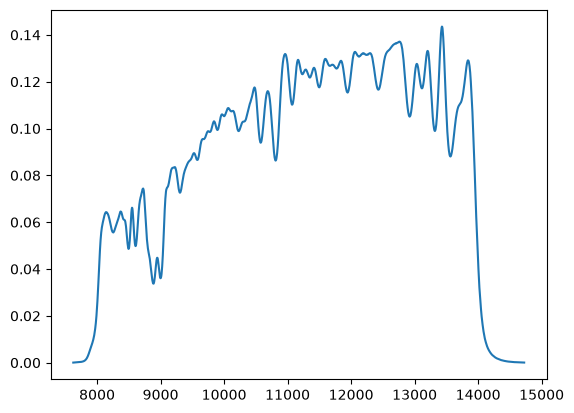

In [8]:
import numpy as onp
nicmosbp = onp.loadtxt("HST_NICMOS1.F110W.dat")

N_wavels = len(nicmosbp[:,0])
plt.plot(nicmosbp[:,0], nicmosbp[:,1])
plt.show()

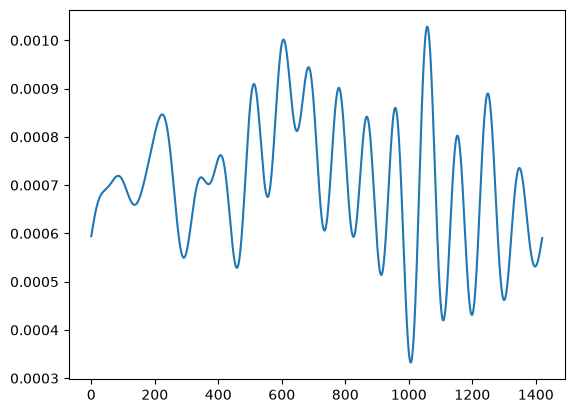

In [9]:
key = jr.PRNGKey(15)
N = N_wavels #int(1420/2) #
# Create a complex array of zeros
spectrum = np.zeros(N, dtype=np.complex64)
freqs = np.fft.fftfreq(N)
fmax = 0.025*np.max(freqs)

# Random amplitudes and phases
amp_key, phase_key = jr.split(key)
random_amplitudes = jr.normal(amp_key, shape=(N,)) 
random_phases = jr.uniform(phase_key, shape=(N,), minval=0.0, maxval=2 * np.pi)

# Assign complex values
spectrum = random_amplitudes * np.exp(1j * random_phases)

# Make symmetric to ensure real time-domain signal
# Copy positive freqs into negative side
def make_hermitian(spec):
    spec = spec.at[1:N//2].set(spec[1:N//2])
    spec = spec.at[-(N//2)+1:].set(np.conj(spec[1:N//2][::-1]))
    return spec

spectrum = make_hermitian(spectrum)

signal = np.fft.ifft(spectrum).real
spectrum_filtered = spectrum.at[np.abs(freqs) > fmax].set(0)
signal_filtered = np.fft.ifft(spectrum_filtered).real

if np.min(signal_filtered) <= 0:
    signal_filtered += -2*np.min(signal_filtered)

# make it sum to 1 (normalise)
signal_filtered = signal_filtered/np.sum(signal_filtered)

x = np.linspace(0, 1, N)

# this just needs a maximum of 1
win = 0.5 * (np.tanh((x - 0.05) * 60) - np.tanh((x - 0.95) * 60))

plt.plot(signal_filtered)
plt.show()

In [10]:
eps = 1e-15
class CombinedSpectrum(dl.Spectrum):
    wavelengths: Array
    filt_weights: Array
    basis_weights: Array
    weights: Array
    flux: float

    def __init__(self, wavels, filt_weights, basis_weights):
        self.wavelengths = np.asarray(wavels, dtype=float)
        self.filt_weights = np.asarray(filt_weights, dtype=float)
        self.basis_weights = np.asarray(basis_weights, dtype=float)

        spec_w = self.spec_weights()
        weights = self.filt_weights * spec_w
        self.weights = weights / weights.sum()
        self.flux = np.sum(spec_w)

    def spec_weights(self):
        raise NotImplementedError

    def normalise(self):
        return self


class CombinedBasisSpectrum(CombinedSpectrum):
    basis_vects: Array

    def __init__(self, wavels, filt_weights, basis_weights, basis):
        self.basis_vects = np.asarray(basis, dtype=float)
        super().__init__(wavels, filt_weights, basis_weights)

    def spec_weights(self):
        return np.maximum(np.sum(self.basis_vects * self.basis_weights, axis=1), eps)
        # return 10 ** (np.sum(self.basis_vects * self.basis_weights, axis=1))

In [11]:
wf_npixels = 128
diameter = 2.4
secondary_diameter = 0.305
strut_width = 0.038
wf_oversample = 5

coords = dlu.pixel_coords(wf_npixels*wf_oversample, diameter)

primary = dlu.circle(coords, diameter/2)
secondary = dlu.circle(coords, secondary_diameter/2, True)
spiders = dlu.spider(coords, strut_width, np.array([45, 135, 225, 315]))

aperture = dlu.combine(np.array([primary, secondary, spiders]), wf_oversample)
aperture_layer = dl.TransmissiveLayer(aperture, True)

layers = [
    (
        'aperture',
        aperture_layer
    )
]

psf_npixels = 128
psf_pixel_scale = 0.0432# e.g. nicmos IR
oversample = 3

optics = dl.AngularOpticalSystem(
    wf_npixels=wf_npixels,
    diameter=diameter,
    layers=layers,
    psf_npixels=psf_npixels,
    psf_pixel_scale=psf_pixel_scale,
    oversample=oversample
)

# Generate a class which just takes unnormalised flux as the spectrum
# Perhaps clips to only propagate above zero?
# Do wavelengths in nm
# wlmin_data = 800e-9
# wlmax_data = 1400e-9
n_wavels_data = N

# wavelengths_data = np.linspace((wlmin_data), (wlmax_data), n_wavels_data)
wavelengths_data = nicmosbp[:,0] * 1e-10
wavelengths_data = 0.5*(wavelengths_data - np.median(wavelengths_data)) + np.median(wavelengths_data)
wlmin_data = np.min(wavelengths_data)
wlmax_data = np.max(wavelengths_data)

log_flux_data = 8 # billion photons?

nbasis = n_wavels_data
# bandpass = win
bandpass = nicmosbp[:,1]

spectrum_bins = CombinedBasisSpectrum(wavelengths_data, bandpass, np.ones(nbasis), np.eye(nbasis))

source_data = dl.PointSource(
    spectrum=spectrum_bins
)

detector = dl.LayeredDetector(
    [dl.detector_layers.Downsample(oversample)]
)

model_data = dl.Telescope(optics, source_data, detector)

def model_psf(spectrum, instrument):
    old_spec = instrument.get("source.spectrum")

    new_spec = CombinedBasisSpectrum(
        wavels=old_spec.wavelengths,
        filt_weights=old_spec.filt_weights,
        basis_weights=spectrum,
        basis=old_spec.basis_vects,
    )

    telescope = instrument.set("source.spectrum", new_spec)
    telescope = telescope.set("source.flux", telescope.get("source.spectrum").flux)
    return telescope.model()
    
injected_spectrum = (signal_filtered) * 10**log_flux_data
# injected_spectrum = np.log10(signal_filtered) + log_flux_data

# plt.plot(injected_spectrum)
img_full = model_psf(injected_spectrum, model_data)
data = jr.poisson(jr.PRNGKey(0), img_full)

In [12]:
import dLux as dl
import jax
import jax.numpy as np
from jax import vmap


# -------------------------------------------------
# 0. A tiny monochromatic spectrum object
# -------------------------------------------------
# This reuses your existing CombinedBasisSpectrum machinery with 1 wavelength.
def monochromatic_spectrum(lam):
    return CombinedBasisSpectrum(
        wavels=np.array([lam]),
        filt_weights=np.array([1.0]),
        basis_weights=np.array([1.0]),
        basis=np.array([[1.0]]),
    )


# -------------------------------------------------
# 1. Pre-detector optical image at one wavelength
# -------------------------------------------------
def optics_image_lambda(lam, instrument):
    """
    Returns the optical image before the detector, while preserving the current
    source object (including source.position).

    Only the source spectrum is replaced by a monochromatic spectrum.
    """
    mono_spec = monochromatic_spectrum(lam)

    source = instrument.get("source")
    source = source.set("spectrum", mono_spec)
    source = source.set("flux", 1.0)  # unit source flux for basis image

    optics = instrument.optics
    # In dLux this is typically the source propagated through the optics.
    # If your local version uses a slightly different call, this is the only
    # line you should need to swap.
    return source.model(optics)


# -------------------------------------------------
# 2. Optical image and d/dlambda of optical image
# -------------------------------------------------
def optics_image_and_dlambda(lam, instrument):
    f = lambda x: optics_image_lambda(x, instrument)
    img = f(lam)
    dimg_dlam = jax.jacfwd(f)(lam)
    return img, dimg_dlam


# -------------------------------------------------
# 3. Evaluate those on the coarse wavelength grid
# -------------------------------------------------
def coarse_optics_images_and_derivs(wavelengths_coarse, instrument):
    imgs, dimgs = vmap(
        lambda lam: optics_image_and_dlambda(lam, instrument)
    )(wavelengths_coarse)

    # imgs.shape  = (Ncoarse, nx, ny)
    # dimgs.shape = (Ncoarse, nx, ny)
    return imgs, dimgs


# -------------------------------------------------
# 4. Dense fine-grid weights -> Hermite node coefficients
# -------------------------------------------------
def hermite_node_coeffs(wavelengths_fine, dense_weights, wavelengths_coarse):
    """
    For
        sum_j dense_weights[j] * O(lambda_fine[j]),
    compute coefficients multiplying coarse-node optical images and
    their wavelength derivatives under piecewise cubic Hermite interpolation.
    """
    wavelengths_fine = np.asarray(wavelengths_fine, dtype=float)
    dense_weights = np.asarray(dense_weights, dtype=float)
    wavelengths_coarse = np.asarray(wavelengths_coarse, dtype=float)

    n_coarse = wavelengths_coarse.size

    idx = np.searchsorted(wavelengths_coarse, wavelengths_fine, side="right") - 1
    idx = np.clip(idx, 0, n_coarse - 2)

    lam0 = wavelengths_coarse[idx]
    lam1 = wavelengths_coarse[idx + 1]
    dlam = lam1 - lam0

    t = (wavelengths_fine - lam0) / dlam

    h00 =  2*t**3 - 3*t**2 + 1
    h10 =      t**3 - 2*t**2 + t
    h01 = -2*t**3 + 3*t**2
    h11 =      t**3 -     t**2

    coeff_val = np.zeros(n_coarse, dtype=dense_weights.dtype)
    coeff_der = np.zeros(n_coarse, dtype=dense_weights.dtype)

    coeff_val = coeff_val.at[idx].add(dense_weights * h00)
    coeff_val = coeff_val.at[idx + 1].add(dense_weights * h01)

    coeff_der = coeff_der.at[idx].add(dense_weights * (dlam * h10))
    coeff_der = coeff_der.at[idx + 1].add(dense_weights * (dlam * h11))

    return coeff_val, coeff_der


# -------------------------------------------------
# 5. Apply detector once at the end
# -------------------------------------------------
def apply_detector(optical_image, instrument):
    detector = instrument.detector
    pixel_scale = instrument.optics.psf_pixel_scale
    oversample = instrument.optics.oversample
    pscale = pixel_scale/oversample
    psf = dl.PSF(optical_image, pscale)

    # If your detector object uses a slightly different method name,
    # this is the other line you may need to swap.
    return detector.model(psf)


# -------------------------------------------------
# 6. Hermite forward model: optics interpolation first, detector last
# -------------------------------------------------
def model_psf_hermite(spectrum, instrument, wavelengths_coarse):
    """
    spectrum:
        Same meaning as in your current model_psf. If source.spectrum is a
        CombinedBasisSpectrum, this can be the basis coefficients.

    instrument:
        Current Telescope(optics, source, detector). Source position etc. are kept.

    wavelengths_coarse:
        Coarse wavelength nodes where the optical image and d/dlambda are evaluated.
    """
    old_spec = instrument.get("source.spectrum")

    # reconstruct dense fine-grid spectrum from basis coefficients
    spec_w = np.maximum(old_spec.basis_vects @ spectrum, eps) # non log
    # spec_w = 10 ** (old_spec.basis_vects @ spectrum) # log

    # dense per-wavelength weights before normalisation
    dense_weights = old_spec.filt_weights * spec_w

    # same overall normalisation convention as your original model_psf
    flux_prefactor = spec_w.sum() / dense_weights.sum()

    # scalar coefficients multiplying coarse-node optical images/derivatives
    coeff_val, coeff_der = hermite_node_coeffs(
        wavelengths_fine=old_spec.wavelengths,
        dense_weights=dense_weights,
        wavelengths_coarse=wavelengths_coarse,
    )

    # evaluate pre-detector optical images and wavelength derivatives
    imgs, dimgs = coarse_optics_images_and_derivs(wavelengths_coarse, instrument)

    # reconstruct dense polychromatic optical image
    optical_image = (
        np.tensordot(coeff_val, imgs, axes=(0, 0)) +
        np.tensordot(coeff_der, dimgs, axes=(0, 0))
    )

    optical_image = flux_prefactor * optical_image

    # detector acts once, at the end
    return apply_detector(optical_image, instrument)

In [13]:
n_wavels_model = N

wl_delta = 0# 50e-9
wavelengths_model = np.linspace((wlmin_data-wl_delta), (wlmax_data+wl_delta), n_wavels_model)
nbasis_model = n_wavels_model
bandpass_model = bandpass
spectrum_bins_model = CombinedBasisSpectrum(wavelengths_model, bandpass_model, np.ones(nbasis_model), np.eye(nbasis_model))
source_model = dl.PointSource(
    spectrum=spectrum_bins_model
)

model = dl.Telescope(optics, source_model, detector)

injected_spectrum_model = np.ones(n_wavels_model)/n_wavels_model * 10**log_flux_data # flat injected spectrum, same flux
# injected_spectrum_model = log_flux_data * np.ones(n_wavels_model) - np.log10(n_wavels_model)#np.ones(n_wavels_model)/n_wavels_model * 10**log_flux_data # flat injected spectrum, same flux


# coarse wavelengths:
n_coarse = 50
wavelengths_coarse = np.linspace(wlmin_data, wlmax_data, n_coarse)

img_hermite = model_psf_hermite(injected_spectrum_model, model, wavelengths_coarse)

In [15]:
from zodiax.diffops import hessian
import jax.scipy as jsp

def loss_fn(params, model, data):
    spectrum = params['spectrum']
    #loss = -poisson_loglike_gamma(data, model_psf(spectrum, model)).sum()
    img = model_psf_hermite(spectrum, model, wavelengths_coarse)
    loss = -normal_logpdf(data, img, np.sqrt(img)).sum()
    return loss

params = {
    "spectrum": injected_spectrum_model
}

# let us do preconditioning with the data... this is fine because we are somewhat close to maximum likelihood
# since we can just do a flat spectrum with the same total flux

# upon later consideration.. don't do wrt. data because you get strange eigval trends

# upon even later consideration... DO do wrt. data. trust.
f = lambda params: loss_fn(params, model, data)

H, unflatten = hessian(f, params)

H = 0.5 * (H + H.T) # symmetretise

In [16]:
# Now take appropriate eigvecs and vals

eigvals, eigvecs = np.linalg.eigh(H)

idx = np.argsort(eigvals)[::-1]

eigvals = eigvals[idx]
eigvecs = eigvecs[:, idx]
mode_spectra = np.fft.rfft(eigvecs, axis=0)

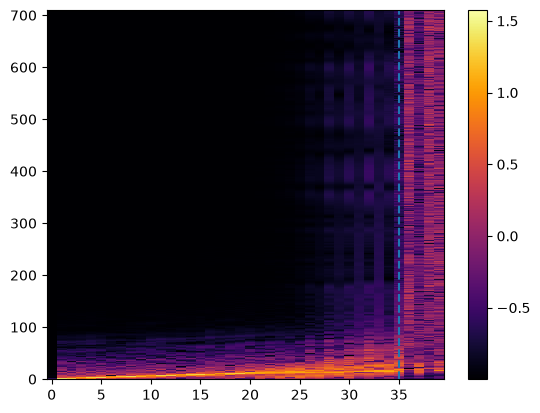

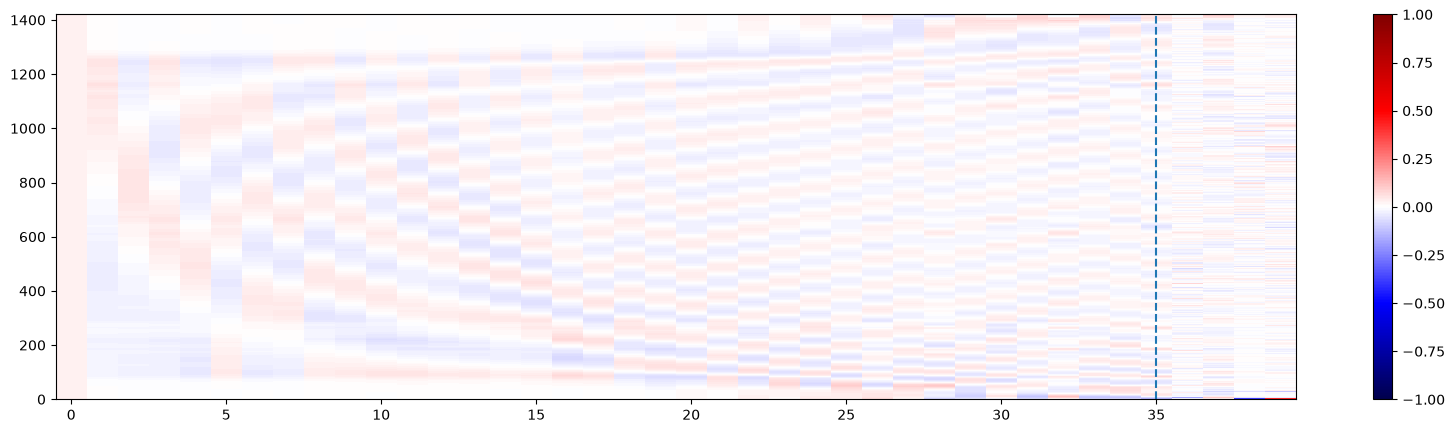

In [17]:
#print(eigvals)
plt.imshow(np.log10(1e-1+ np.abs(mode_spectra[:,:40])), cmap='inferno', aspect='auto', interpolation='none')
plt.axvline(35, ls='--')
plt.colorbar()
plt.show()

plt.figure(figsize=(20,5))
plt.imshow(eigvecs[:,:40], cmap='seismic', aspect='auto', interpolation='none', vmax=1,vmin=-1)
plt.axvline(35, ls='--')
plt.colorbar()
plt.show()

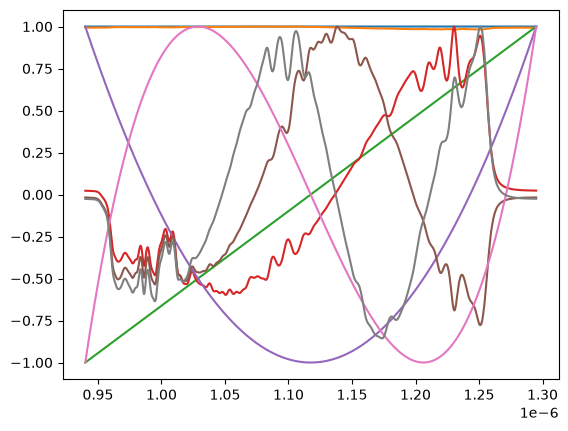

In [ ]:
import numpy as onp
max_order = 3
x_c = np.linspace(-1,1,N)
for n in range(max_order + 1):
    Tn = onp.polynomial.chebyshev.chebval(x_c, [0]*n + [1])
    plt.plot(wavelengths_data, Tn, label=fr"$T_{n}(x)$")

    plt.plot(wavelengths_data, eigvecs[:,n]/np.max(np.abs(eigvecs[:,n])))

plt.show()

In [58]:
import numpy as np
import matplotlib.pyplot as plt

def fourier_mode_quality(eigvecs, skip=1, band=4, eps=1e-30):
    """
    eigvecs: shape (n_wavelengths, n_modes)
    skip: skip flux-normalisation / DC-like mode
    band: half-width in Fourier bins for local spectral-purity metric
    """

    mode_index = np.arange(skip, eigvecs.shape[1])
    x = np.asarray(eigvecs[:, skip:], dtype=float)

    # Remove DC component so the metric is about oscillatory structure.
    x = x - np.mean(x, axis=0, keepdims=True)

    # Normalise modes so coefficient scaling does not matter.
    x = x / np.sqrt(np.sum(x**2, axis=0, keepdims=True) + eps)

    # Fourier power
    F = np.fft.rfft(x, axis=0)
    P = np.abs(F)**2

    # Ignore DC bin after mean subtraction
    P[0, :] = 0.0

    # Normalised Fourier power distribution
    Ptot = np.sum(P, axis=0, keepdims=True)
    p = P / (Ptot + eps)

    # 1. Effective number of Fourier bins
    n_eff = 1.0 / (np.sum(p**2, axis=0) + eps)

    # 2. Normalised spectral entropy, optional
    nfreq = p.shape[0]
    entropy = -np.sum(p * np.log(p + eps), axis=0) / np.log(nfreq)

    # 3. Local spectral purity:
    # fraction of power contained in the best narrow Fourier band
    kernel = np.ones(2 * band + 1)
    band_power = np.apply_along_axis(
        lambda a: np.convolve(a, kernel, mode="same"),
        axis=0,
        arr=p,
    )
    purity = np.max(band_power, axis=0)

    return mode_index, n_eff, entropy, purity

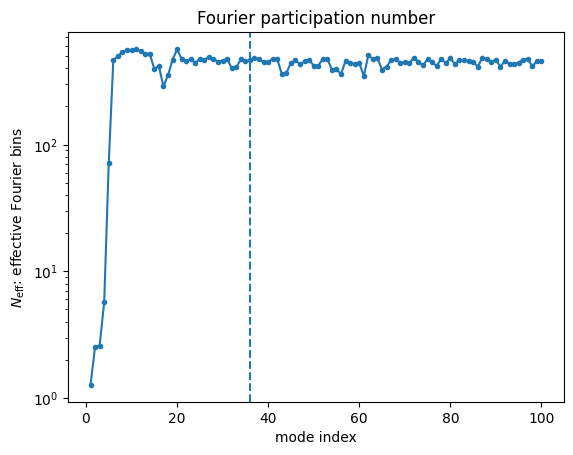

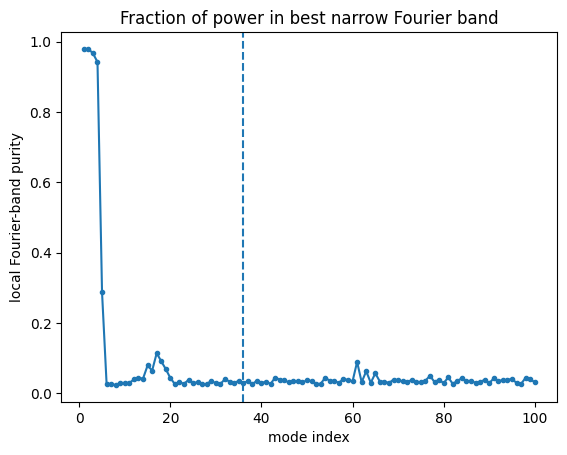

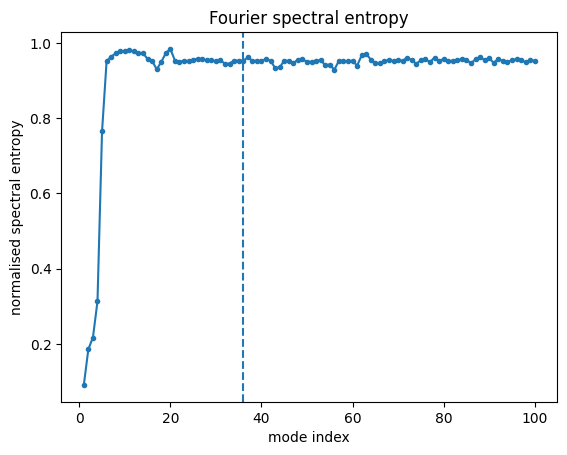

In [59]:
mode, n_eff, entropy, purity = fourier_mode_quality(eigvecs, skip=1, band=4)

nmodes_1234 = 100
plt.figure()
plt.semilogy(mode[:nmodes_1234], n_eff[:nmodes_1234], ".-")
plt.axvline(36, ls='--')
plt.xlabel("mode index")
plt.ylabel(r"$N_{\rm eff}$: effective Fourier bins")
plt.title("Fourier participation number")
plt.show()

plt.figure()
plt.plot(mode[:nmodes_1234], purity[:nmodes_1234], ".-")
plt.axvline(36, ls='--')
plt.xlabel("mode index")
plt.ylabel("local Fourier-band purity")
plt.title("Fraction of power in best narrow Fourier band")
plt.show()

plt.figure()
plt.plot(mode[:nmodes_1234], entropy[:nmodes_1234], ".-")
plt.axvline(36, ls='--')
plt.xlabel("mode index")
plt.ylabel("normalised spectral entropy")
plt.title("Fourier spectral entropy")
plt.show()

In [60]:
score = np.log10(n_eff)

# light smoothing so one weird mode does not dominate
score_smooth = np.convolve(score, np.ones(3) / 3, mode="same")

# ignore first few modes when finding the jump
min_i = 3
j = min_i + np.argmax(np.diff(score_smooth)[min_i:])

first_bad_mode = mode[j + 1]

print("First likely cooked mode:", first_bad_mode)

First likely cooked mode: 5


In [61]:
# trying to fit any more than 22 modes causes NGD to break
# and for got reason?! I think..
# Think its better to just fit the first 20
# then do next 20 (or however many you can constrain) with BFGS
# really shouldn't do any more modes than it goes negative for
nbasis_fit = 18#36
print(nbasis_fit)


# project my flat spectrum onto this new basis
injected_spectrum_fit = np.linalg.lstsq(eigvecs[:, :nbasis_fit], injected_spectrum_model)[0]

spectrum_bins_fit = CombinedBasisSpectrum(wavelengths_model, bandpass_model, injected_spectrum_fit, eigvecs[:,:nbasis_fit])

source_fit = dl.PointSource(
    spectrum=spectrum_bins_fit
)

model_fit = dl.Telescope(optics, source_fit, detector)

18


In [62]:
import equinox as eqx
import optax
from zodiax import optimisation as opt
from tqdm import tqdm
from jax.flatten_util import ravel_pytree
import jax.numpy as np

# JIT and grad transform the loss function
loss_grad_fn = eqx.filter_jit(eqx.filter_value_and_grad(loss_fn))

params = {'spectrum': injected_spectrum_fit}

optimisers = {'spectrum': optax.sgd(1e-1)}

# Now we map the optimisers to the parameters and get the initial state
optim, state = opt.map_optimisers(params, optimisers)

# for natural gradient descent, use the covariance matrix
# in our case, just the inverse of the eigvals
C = np.diag(1/eigvals[:nbasis_fit])
# but some have too high covariance and break everything
# so do npmin with 1e14 (heuristic)

# Now we can run a simple optimisation loop
losses = []
params_out = []
pbar = tqdm(range(100))
for step in pbar:
    loss, grads = loss_grad_fn(params, model_fit, data)

    # precondition updates with the covariance matrix
    G, unflatten = ravel_pytree(grads)

    # blocking grads
    # mode_idx = np.arange(G.shape[0])
    # start_steps = block_every * (mode_idx // block_size)
    # active = (step >= start_steps).astype(G.dtype)
    # G = G * active
    # blocking grads

    grads = unflatten(np.dot(G, C))
    
    # continue the gradient descent
    updates, state = optim.update(grads, state)
    params = optax.apply_updates(params, updates)
    pbar.set_postfix(log_loss=f"{np.log10(loss):.4f}")
    losses.append(loss)
    params_out.append(params)

losses = np.array(losses)
# 3.1115
# 3.1108
# 3.1107
# 3.1131

100%|██████████| 100/100 [00:31<00:00,  3.19it/s, log_loss=4.8042]


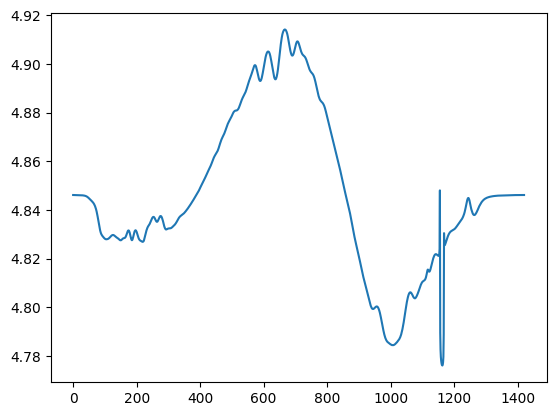

In [63]:
spectrum_new = np.maximum(eigvecs[:,:nbasis_fit] @ params_out[-1]['spectrum'], 1e-7)
plt.plot(spectrum_new)
plt.show()

In [193]:
# truncate any negatives
spectrum_new = np.maximum(eigvecs[:,:nbasis_fit] @ params_out[-1]['spectrum'], 1e-7)

params_new = {
    'spectrum':
    spectrum_new
}

# get the observed information
f_new = lambda params: loss_fn(params, model, data)

H_new, unflatten_new = batching.hessian(f_new, params_new)

In [194]:
# construct new basis from observed information
eigvals_new, eigvecs_new = np.linalg.eigh(H_new)

idx_new = np.argsort(eigvals_new)[::-1]

eigvals_new = eigvals_new[idx_new]
eigvecs_new = eigvecs_new[:, idx_new]
mode_spectra_new = np.fft.rfft(eigvecs_new, axis=0)

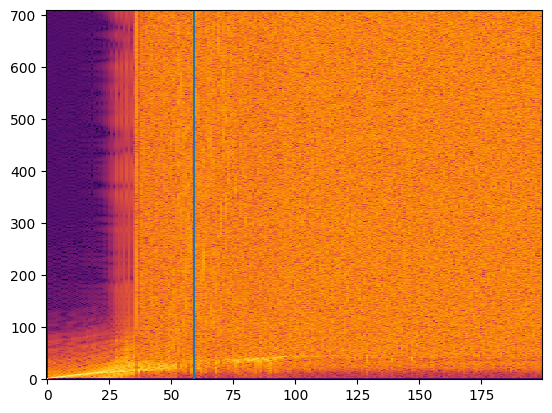

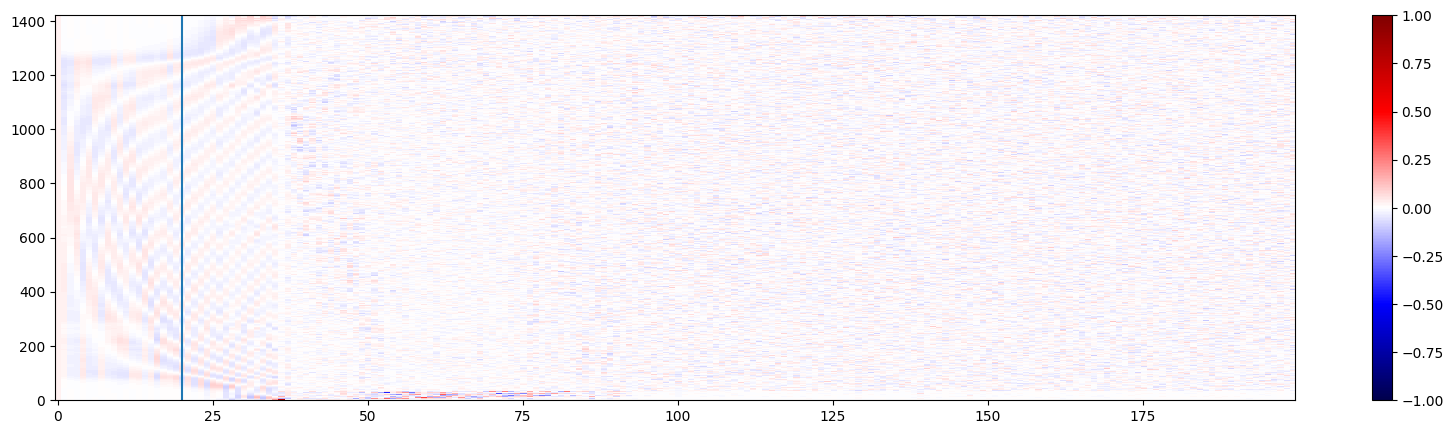

In [195]:
plt.imshow(np.log10(np.abs(mode_spectra_new[:,:200]+1e-3)), cmap='inferno', aspect='auto', interpolation='none')
plt.axvline(59)
# plt.colorbar()
plt.show()

plt.figure(figsize=(20,5))
plt.imshow(eigvecs_new[:,:200], cmap='seismic', aspect='auto', interpolation='none', vmax=1,vmin=-1)
plt.axvline(20)
plt.colorbar()
plt.show()

In [196]:
# with recomputed hessian do same thing

# perhaps with all 200 modes? no because negative try abs
nbasis_fit_2 = 23#46
# Basically choose the number of modes such that the maximum likelihood spectrum
# has no part in the negative
# basically modes above this become unconstrained
print(nbasis_fit_2)


# project my flat spectrum onto this new basis
injected_spectrum_fit_2 = np.linalg.lstsq(eigvecs_new[:, :nbasis_fit_2], spectrum_new)[0]

spectrum_bins_fit_2 = CombinedBasisSpectrum(wavelengths_model, bandpass_model, injected_spectrum_fit_2, eigvecs_new[:,:nbasis_fit_2])

source_fit_2 = dl.PointSource(
    spectrum=spectrum_bins_fit_2
)

model_fit_2 = dl.Telescope(optics, source_fit_2, detector)

C_new = np.diag(1/eigvals_new[:nbasis_fit_2])

23


In [197]:
# do bfgs on the increased number of basis vecs
import optimistix as optx

args = (model_fit_2, data)

# reference point: this should become zero in scaled space
params_ref = {
    "spectrum": injected_spectrum_fit_2
}

# usually use standard deviations, not variances
# abs because some negative
scale = np.sqrt(np.diag(np.abs(C_new)))

def to_scaled(params):
    return {
        "spectrum": (params["spectrum"] - params_ref["spectrum"]) / scale
    }

def from_scaled(params_scaled):
    return {
        "spectrum": params_ref["spectrum"] + params_scaled["spectrum"] * scale
    }

params0_scaled = to_scaled(params_ref)

def loss_fn_optx(params, args):
    model, data = args
    spectrum = params['spectrum']
    img = model_psf_hermite(spectrum, model, wavelengths_coarse)
    loss = -normal_logpdf(data, img, np.sqrt(img)).sum()
    return loss

def loss_fn_optx_scaled(params_scaled, args):
    params = from_scaled(params_scaled)
    return loss_fn_optx(params, args)

solver = optx.BFGS(
    rtol=1e-10,
    atol=0.0,
    #norm=optx.rms_norm,
    verbose=False,
)

sol = optx.minimise(
    loss_fn_optx_scaled,
    solver,
    params0_scaled,
    args,
    max_steps=2048,
    throw=False,
)

params_final = from_scaled(sol.value)

print("result:", sol.result)
print("stats:", sol.stats)
print("start log loss:", np.log10(loss_fn_optx(params_ref, args)))
print("final log loss:", np.log10(loss_fn_optx(from_scaled(sol.value), args)))

# 4.394650118279899
# 4.394604729059547
# 4.39460672611341

result: optimistix._solution.RESULTS<>
stats: {'max_steps': 2048, 'num_steps': Array(43, dtype=int64, weak_type=True)}
start log loss: 4.80312359516462
final log loss: 4.803115112608949


42137.36132559891


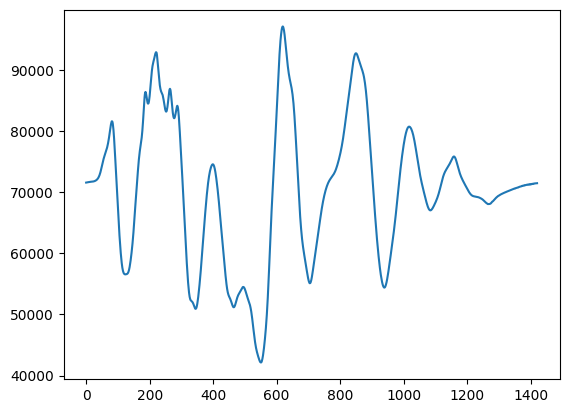

In [198]:
spectrum_found = np.maximum(eigvecs_new[:,:nbasis_fit_2] @ params_final['spectrum'], -1e7)
print(spectrum_found[np.argmin(spectrum_found)])
plt.plot(spectrum_found)
plt.show()

In [199]:
# spectrum_found = eigvecs_new[:,:nbasis_fit_2] @ params_final['spectrum']

params_found = {
    'spectrum':
    spectrum_found
}

# get the observed information
f_found = lambda params: loss_fn(params, model, data)

H_found, unflatten_found = batching.hessian(f_found, params_found)

In [200]:
# construct new basis from observed information
eigvals_found, eigvecs_found = np.linalg.eigh(H_found)

idx_found = np.argsort(eigvals_found)[::-1]

eigvals_found = eigvals_found[idx_found]
eigvecs_found = eigvecs_found[:, idx_found]
mode_spectra_found = np.fft.rfft(eigvecs_found, axis=0)

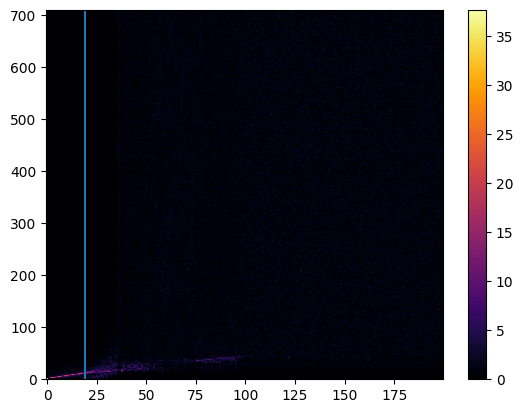

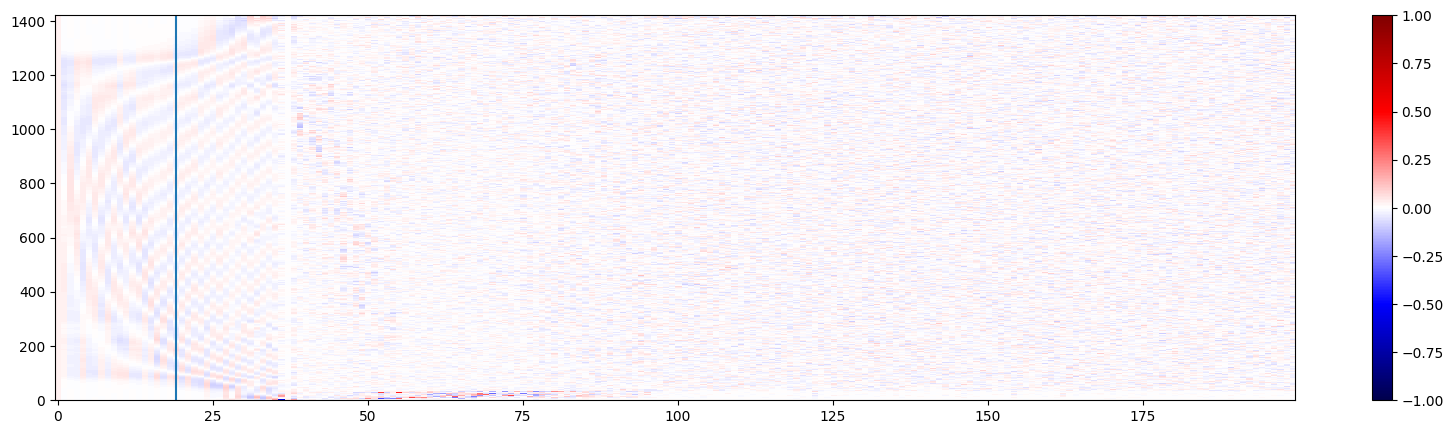

In [201]:
plt.imshow(np.abs(mode_spectra_found[:,:200]), cmap='inferno', aspect='auto', interpolation='none')
plt.axvline(19)
plt.colorbar()
plt.show()

plt.figure(figsize=(20,5))
plt.imshow(eigvecs_found[:,:200], cmap='seismic', aspect='auto', interpolation='none', vmax=1,vmin=-1)
plt.axvline(19)
plt.colorbar()
plt.show()

In [202]:
coeffs_recov = np.linalg.solve(eigvecs_found, spectrum_found)

coeffs_inject = np.linalg.solve(eigvecs_found, injected_spectrum)

cov_found = np.diag(1/eigvals_found) # this is kinda sus but I think its correct

In [225]:
nmodes_out = 20
spec_var = (eigvecs_found[:,:nmodes_out]**2) @ np.diag(cov_found[:nmodes_out, :nmodes_out])

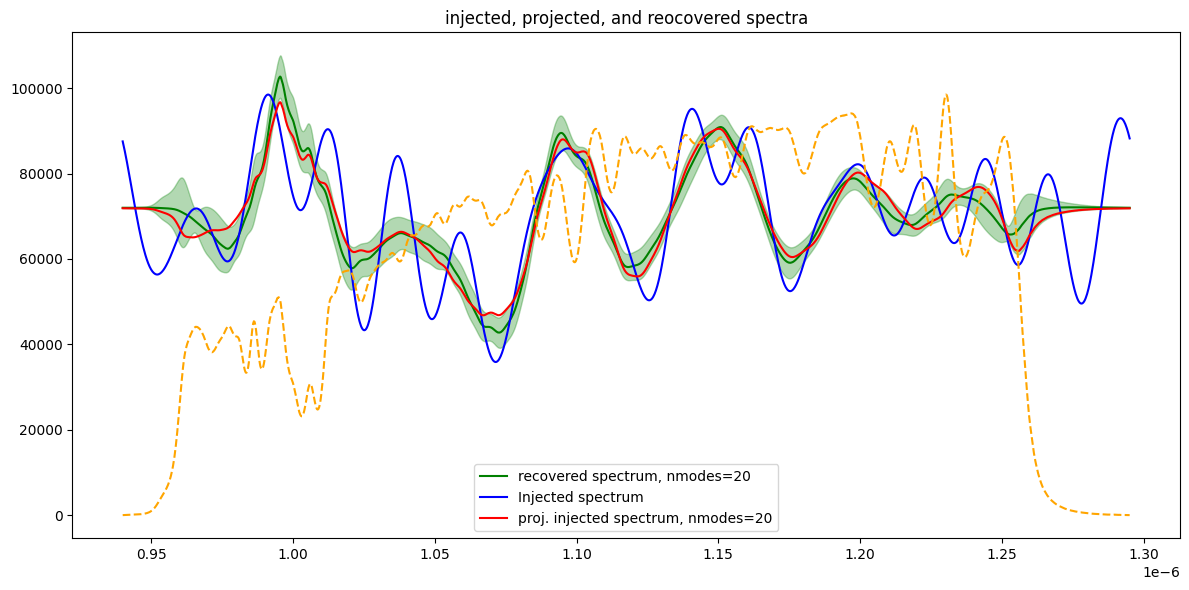

In [226]:
plt.figure(figsize=(12,6))
plt.subplot(1,1,1)
plt.title('injected, projected, and reocovered spectra')

spec_mean = eigvecs_found[:,:nmodes_out] @ coeffs_recov[:nmodes_out]
spec_std = np.sqrt(spec_var)

plt.plot(
    wavelengths_model,
    spec_mean,
    color='green',
    label=f'recovered spectrum, nmodes={nmodes_out}'
)

plt.fill_between(
    wavelengths_model,
    spec_mean - spec_std,
    spec_mean + spec_std,
    color='green',
    alpha=0.3
)

plt.plot(wavelengths_data, injected_spectrum, color='blue', label='Injected spectrum')
plt.plot(wavelengths_data, eigvecs_found[:,:nmodes_out] @ coeffs_inject[:nmodes_out], color='red', label=f'proj. injected spectrum, nmodes={nmodes_out}')
plt.plot(wavelengths_data, bandpass*np.max(injected_spectrum)/np.max(bandpass), ls='--', color='orange')
plt.legend()

# plt.subplot(1,2,2)
# plt.title('residual z-scores of projected v. recovered spectra')
# spectrum_zs = (eigvecs_new[:,:nmodes_out]@coeffs_inject[:nmodes_out] - eigvecs_new[:,:nmodes_out] @ coeffs_recov[:nmodes_out]) / ((1e0)*(np.sqrt((spec_var)))) 
# plt.hist(spectrum_zs, bins=20, density=True)
# zs = np.linspace(-5,5,1000)
# plt.plot(zs, np.exp(-zs**2/2)/np.sqrt(2*np.pi))

plt.tight_layout()
plt.show() 
# this looks like the strat.


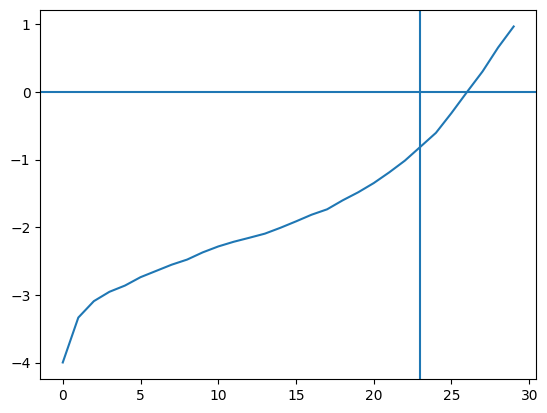

In [207]:
plt.plot(np.log10(np.sqrt(np.diag(cov_found))/coeffs_recov[0])[:30])
plt.axhline(0)
plt.axvline(23)

In [208]:
np.sqrt(np.diag(cov_found))/coeffs_recov[0]

Array([0.00010026, 0.00046243, 0.00080904, ...,        nan,        nan,
              nan], dtype=float64)

In [209]:
(np.sqrt(np.diag(cov_found))/coeffs_recov[0])[28]

Array(4.56173093, dtype=float64)

In [210]:
np.max(np.abs(eigvecs_found[:,0]))

Array(0.02663742, dtype=float64)

In [211]:
np.max(np.abs(eigvecs_found[:,23]))

Array(0.06692851, dtype=float64)

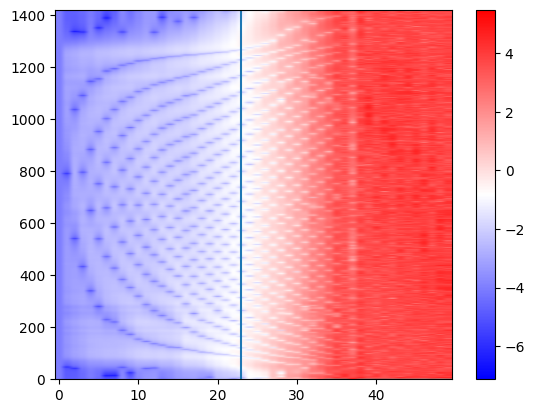

In [212]:
plt.imshow(np.log10(((np.sqrt(np.diag(cov_found)) * np.abs(eigvecs_found))/(coeffs_recov[0] * eigvecs_found[:,0]))[:,:50]) , cmap='bwr', aspect='auto')
plt.colorbar()
plt.axvline(23)
plt.show()

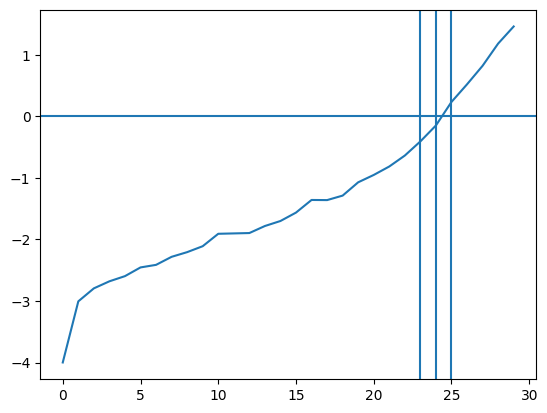

In [213]:
plt.plot(np.log10(np.max(((np.sqrt(np.diag(cov_found)) * np.abs(eigvecs_found))/(coeffs_recov[0] * eigvecs_found[:,0]))[:,:30],axis=0)))
plt.axhline(0)
plt.axvline(23)
plt.axvline(24)
plt.axvline(25)
plt.show()

In [214]:
np.max(((np.sqrt(np.diag(cov_found)) * np.abs(eigvecs_found))/(coeffs_recov[0] * eigvecs_found[:,0]))[:,:40],axis=0)

Array([1.00682796e-04, 9.89780608e-04, 1.60843836e-03, 2.09350705e-03,
       2.53963705e-03, 3.51756282e-03, 3.87146941e-03, 5.22894143e-03,
       6.22951537e-03, 7.77574408e-03, 1.23693764e-02, 1.25413522e-02,
       1.27156791e-02, 1.65425933e-02, 1.99519342e-02, 2.73161031e-02,
       4.37913259e-02, 4.35827971e-02, 5.15559175e-02, 8.47958348e-02,
       1.11598918e-01, 1.53095282e-01, 2.30526486e-01, 3.91161727e-01,
       7.10130445e-01, 1.71047425e+00, 3.30403793e+00, 6.60371405e+00,
       1.51467558e+01, 2.87159961e+01, 5.82682168e+01, 1.99876099e+02,
       8.07714513e+02, 1.44084111e+03, 4.50354107e+03, 2.36453374e+04,
       1.66830245e+05, 3.13037710e+05, 5.72789989e+04, 6.36480641e+04],      dtype=float64)

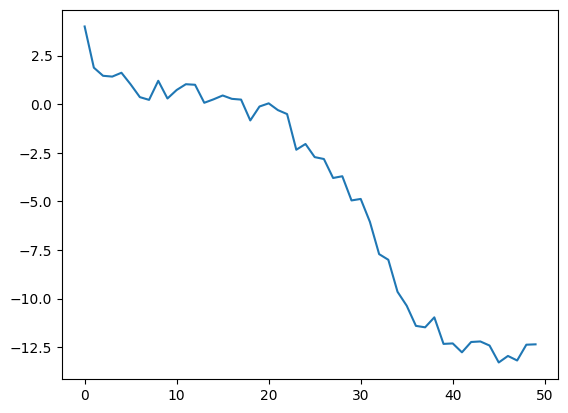

In [215]:
plt.plot(np.log10((np.abs(coeffs_recov)/np.sqrt(np.diag(cov_found)))[:50]))

In [216]:
# heursitc factor 10 -- 18
# around 15

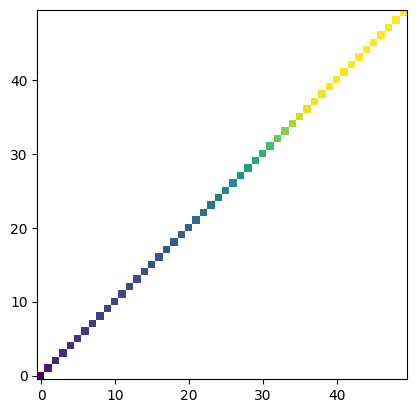

In [217]:
plt.imshow(np.log10(cov_found[:50,:50]))

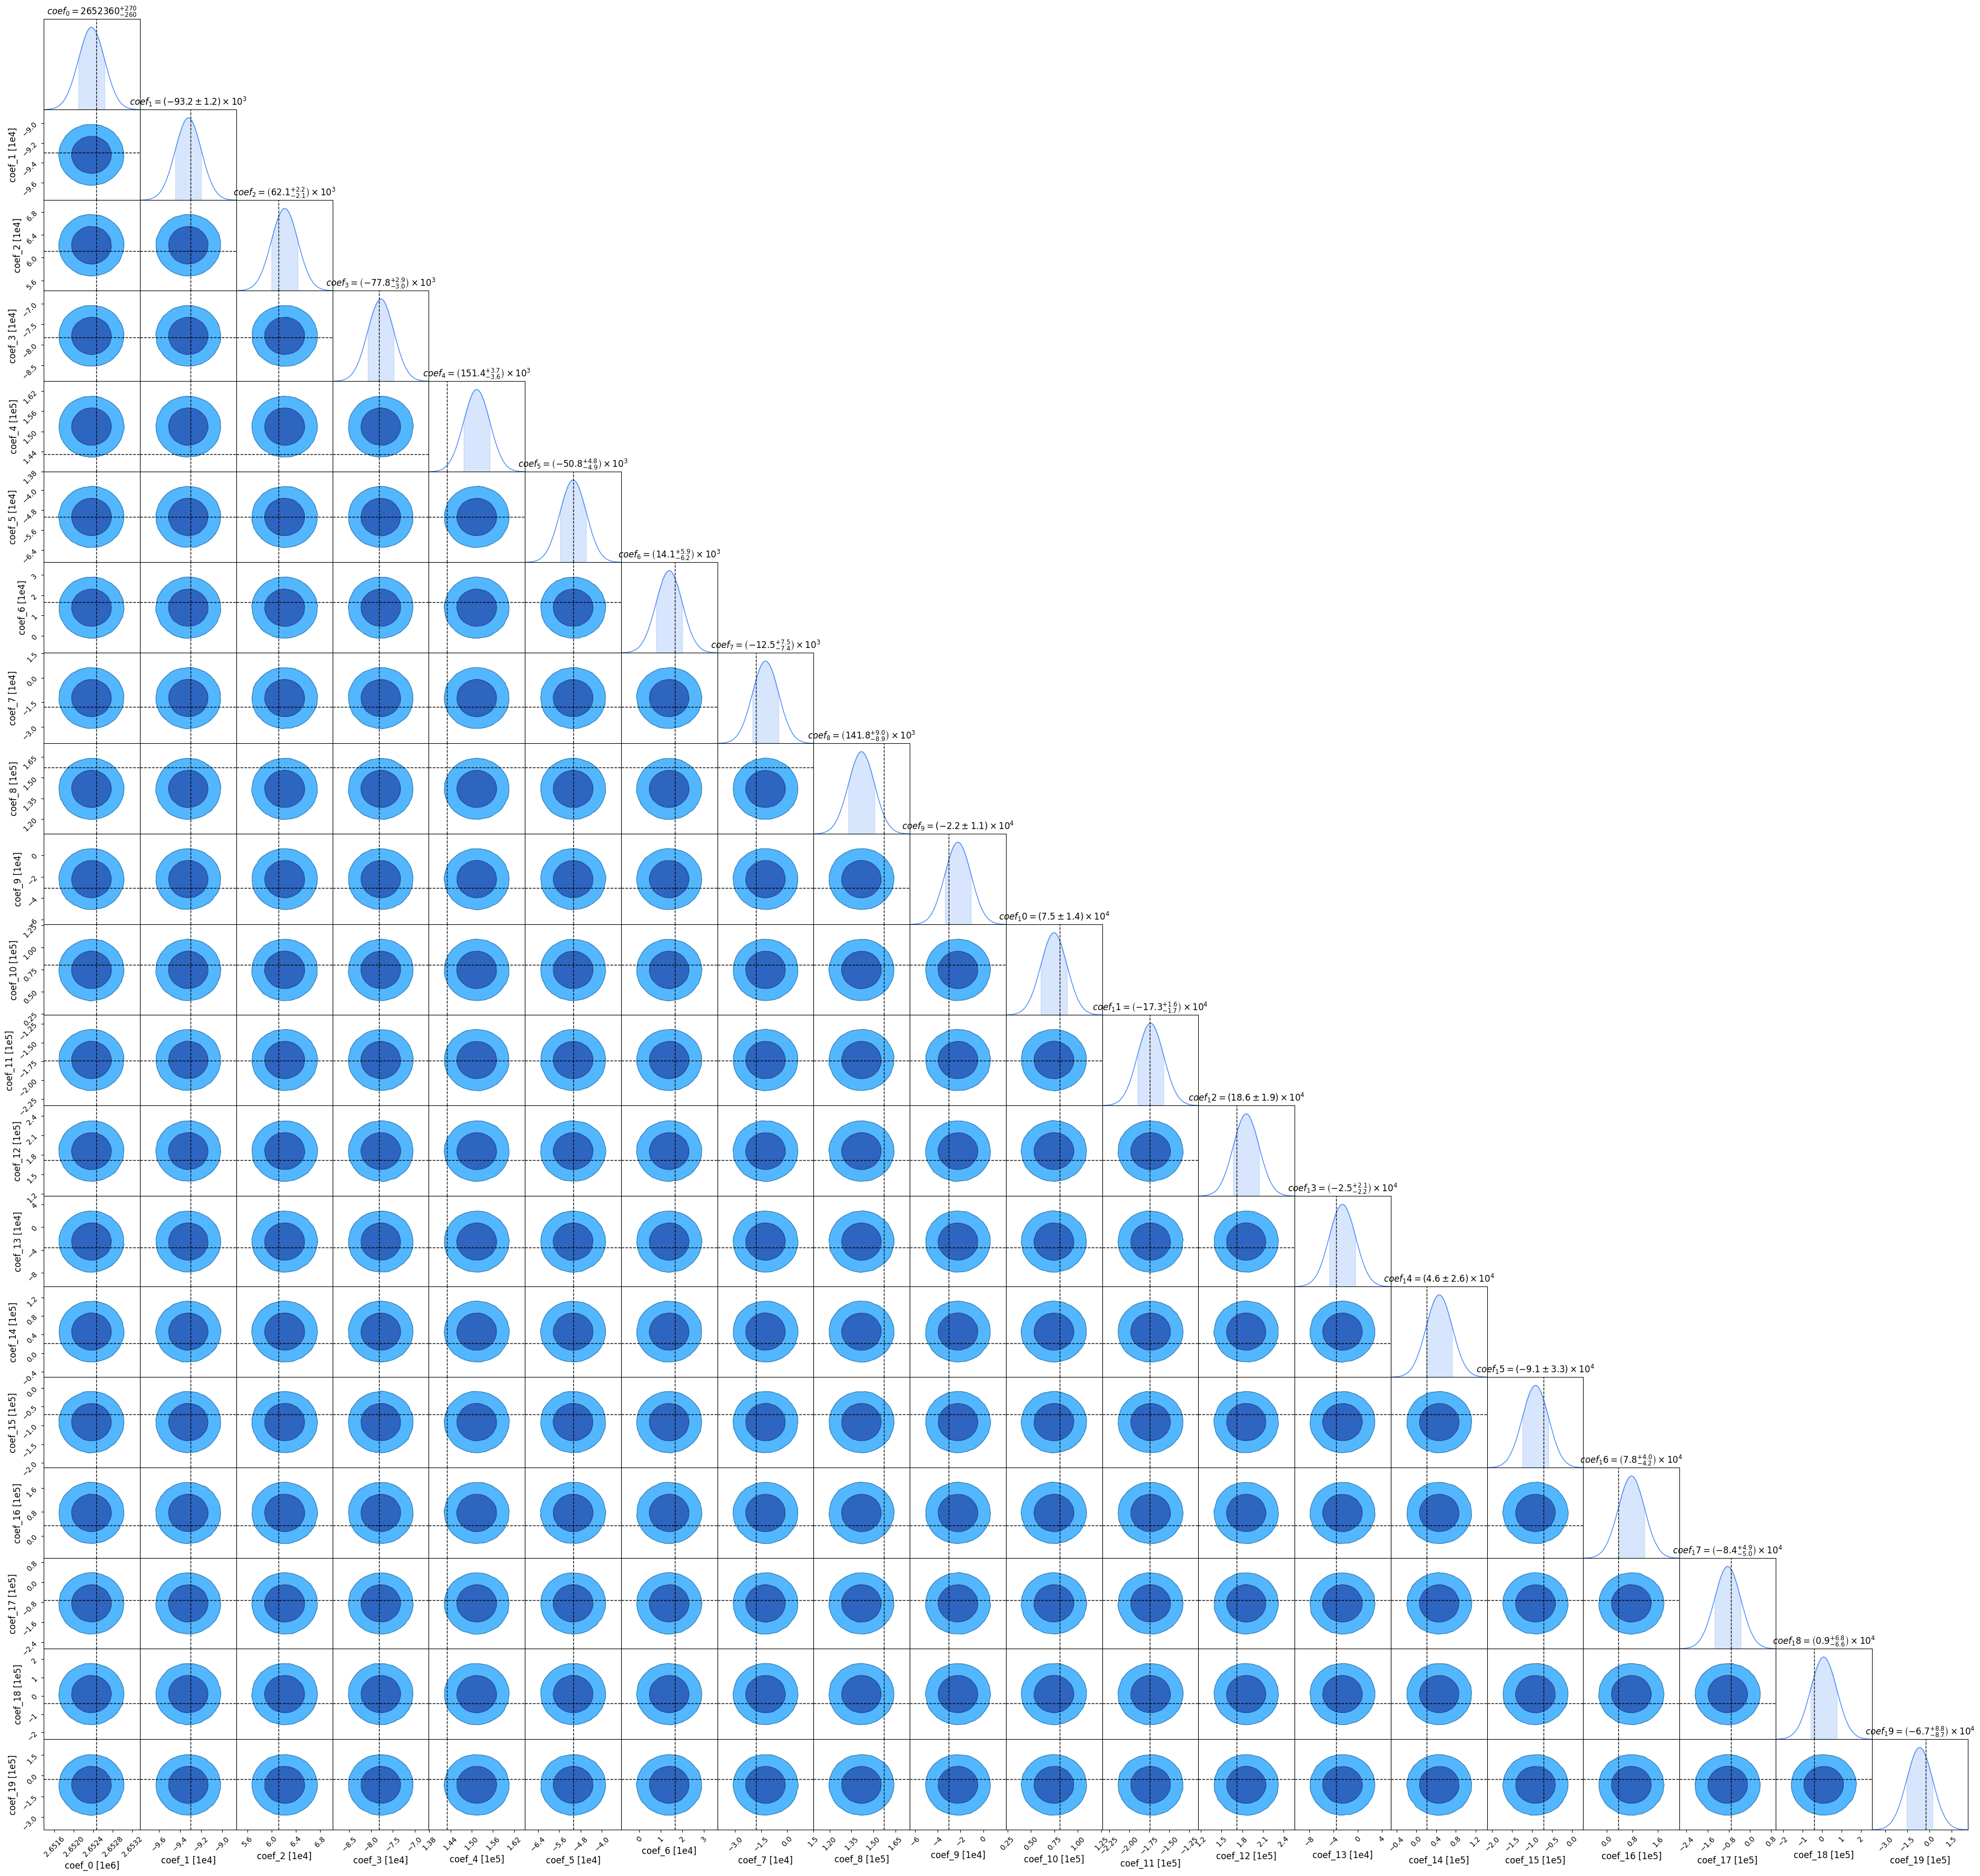

In [227]:
from chainconsumer import ChainConsumer, Chain, Truth

c = ChainConsumer()

ncoeffs_plot = 20
cols = [f"coef_{i}" for i in range(ncoeffs_plot)]

truth_dict = dict(zip(cols, coeffs_inject[:ncoeffs_plot]))
cov_chain = Chain.from_covariance(mean=coeffs_recov[:ncoeffs_plot], covariance=cov_found[:ncoeffs_plot,:ncoeffs_plot], columns=cols, name='hi')
c.add_chain(cov_chain)
c.add_truth(Truth(location=truth_dict))
fig = c.plotter.plot()

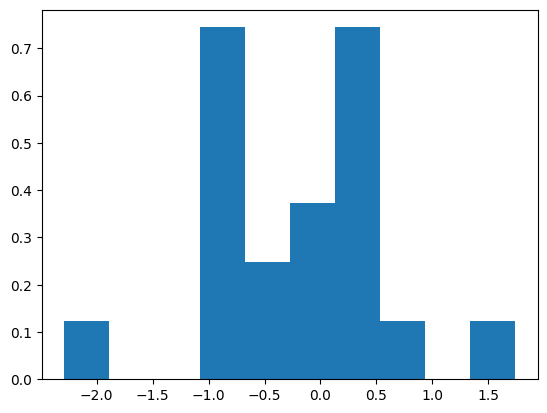

In [230]:
plt.hist(((coeffs_inject - coeffs_recov)/np.sqrt(np.diag(cov_found)))[:20], density=True, bins=10)
plt.show()

In [521]:
{"parameter": coeffs_recov}

{'parameter': Array([ 3.75231536e+06,  7.59056056e+04, -4.56556635e+04, -2.22080705e+05,
         1.21440199e+05, -5.97678095e+04,  1.27466224e+05, -1.10082433e+05,
         1.79407879e+05, -3.25258822e+04,  9.85856025e+04, -1.84641039e+05,
         2.35450263e+05, -1.46868869e+05,  1.61272044e+05, -1.77581203e+03,
         4.63857227e+03,  6.99386487e+03, -1.97540522e+04, -4.44047044e+04,
        -5.57273439e+04,  1.17681656e+05,  3.85696767e+04,  1.00518843e+05,
        -5.19866983e+04, -2.44305615e+05, -2.09039672e+05, -7.97640476e+04,
         3.07532108e+04,  1.11981139e+05, -1.52249800e+05,  8.44158054e+04,
        -1.71767688e+05, -3.72716373e+04,  1.60511351e+05,  8.35618898e+04,
        -2.39366673e+05, -1.65456399e+05, -6.70854709e+04, -2.29804048e+05,
        -7.60369583e+05, -1.69092647e+05, -3.99242400e+04,  1.60648160e+03,
         4.08614194e+04, -4.72053678e+03,  3.69279958e+04,  6.78553062e+03,
        -3.77268610e+04,  1.31660849e+04, -1.97216710e+04,  4.63211786e+02,